In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import analysis

In [8]:
model_a = "logistic_indic-enc"
model_b = "logistic_bow-enc"

df_a = pd.read_csv(Path("metrics") / f"{model_a}.csv")
df_b = pd.read_csv(Path("metrics")/ f"{model_b}.csv")

print(df_a)
print(df_b)

                model  accuracy  run  fold  seed
0  logistic_indic-enc  0.782480    0     0     0
1  logistic_indic-enc  0.778174    0     1     0
2  logistic_indic-enc  0.781589    0     2     0
3  logistic_indic-enc  0.783296    0     3     0
4  logistic_indic-enc  0.781944    0     4     0
              model  accuracy  run  fold  seed
0  logistic_bow-enc  0.785375    0     0     0
1  logistic_bow-enc  0.779287    0     1     0
2  logistic_bow-enc  0.782925    0     2     0
3  logistic_bow-enc  0.784261    0     3     0
4  logistic_bow-enc  0.781424    0     4     0


In [9]:
paired = pd.merge(
    df_a[["seed", "fold", "accuracy"]],
    df_b[["seed", "fold", "accuracy"]],
    on=["seed", "fold"],
    suffixes=("_a", "_b"),
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert (paired["_merge"] == "both").all(), "Missing matching folds"

paired = paired.sort_values(["seed", "fold"])

paired["difference"] = (
    paired["accuracy_b"] - paired["accuracy_a"]
)

print(paired)

   seed  fold  accuracy_a  accuracy_b _merge  difference
0     0     0    0.782480    0.785375   both    0.002895
1     0     1    0.778174    0.779287   both    0.001114
2     0     2    0.781589    0.782925   both    0.001336
3     0     3    0.783296    0.784261   both    0.000965
4     0     4    0.781944    0.781424   both   -0.000520


In [10]:
acc_a = paired["accuracy_a"].to_numpy()
acc_b = paired["accuracy_b"].to_numpy()

print(f"{model_a}: {acc_a.mean():.4f}")
print(f"{model_b}: {acc_b.mean():.4f}")
print(f"Mean difference (B-A): {(acc_b - acc_a).mean():.4f}")

logistic_indic-enc: 0.7815
logistic_bow-enc: 0.7827
Mean difference (B-A): 0.0012


In [5]:
rope = 0.005  # 0.5 percentage points
num_runs = paired["seed"].nunique()

# Check that every run contains the same set of folds
fold_sets = paired.groupby("seed")["fold"].apply(lambda x: set(x))
assert all(f == fold_sets.iloc[0] for f in fold_sets)

posterior = analysis.BenavoliCorrelatedT(
    acc_a,
    acc_b,
    runs=num_runs,
    names=[model_a, model_b]
)

p_a, p_tie, p_b = posterior.probs(rope)

print(f"P(A wins): {p_a:.4f}")
print(f"P(Tie):    {p_tie:.4f}")
print(f"P(B wins): {p_b:.4f}")
print(f"Posterior mean difference: {posterior.mean_diff:.4f}")
print(f"Effect size: {posterior.effect_size:.4f}")

P(A wins): 0.0008
P(Tie):    0.9946
P(B wins): 0.0046
Posterior mean difference: 0.0012
Effect size: 1.4210


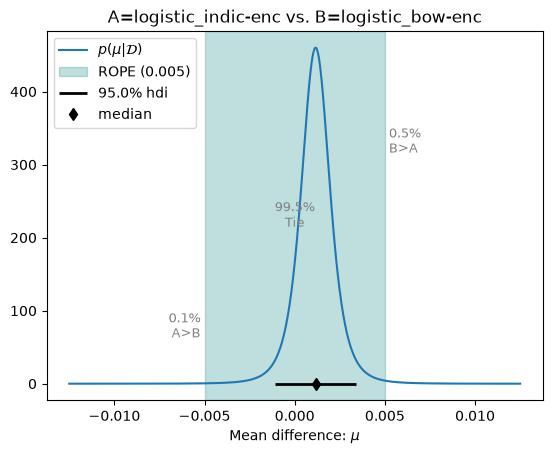

In [6]:
fig, ax = posterior.plot(rope)
plt.show()